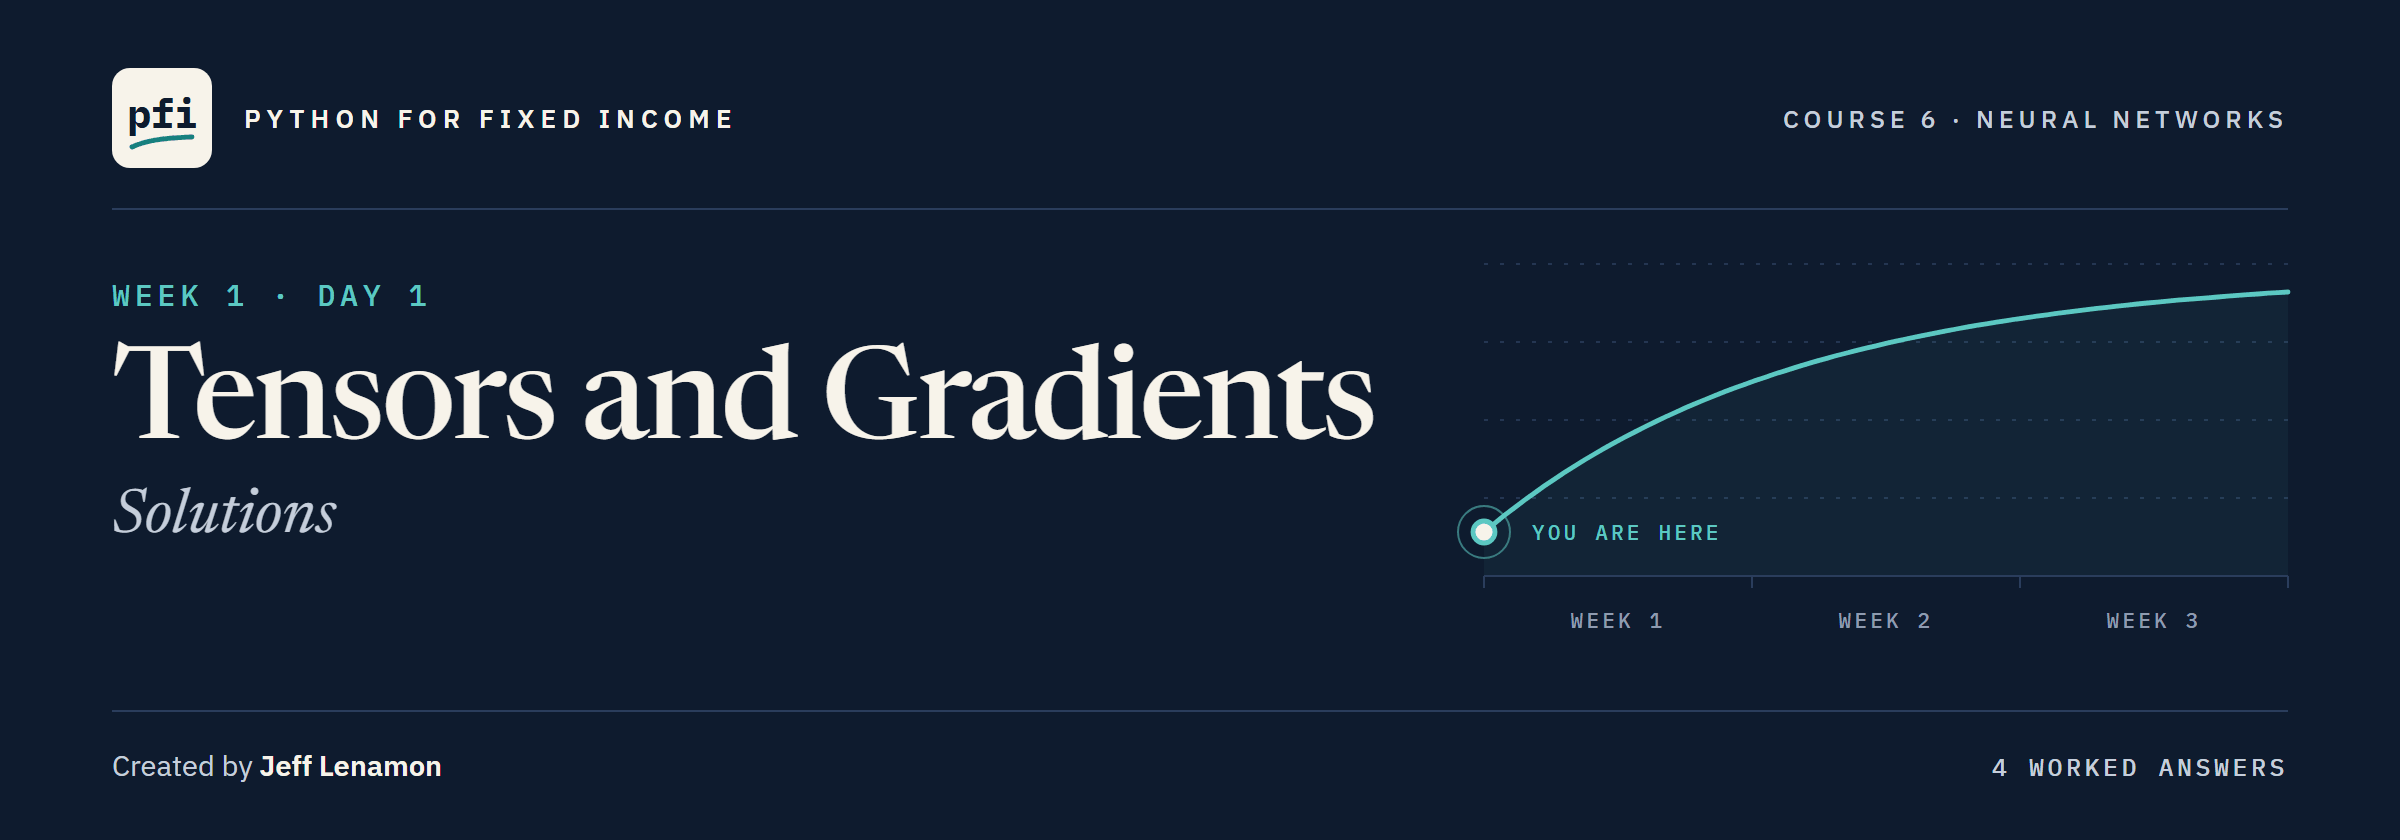

# Tensors and Gradients: Solutions

Week 1, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week1/day1/01_tensors_and_gradients_solutions.ipynb)

# Problem Statement

## Business Context

Courses 4 and 5 fitted logistic regression and boosting on 30,000 credit card accounts, and `fit` did the fitting out of sight.
Course 6 fits neural networks, and every setting it turns, from the learning rate to the optimizer, is a setting of that hidden routine.
So the team takes the routine apart on the smallest network there is, one neuron on one column, and checks each piece against Course 4's Day 6 logistic regression and against TensorFlow.
Today fits on Course 4's 18,000 training accounts and reports once on its 6,000 validation accounts.
Course 4's 6,000 test accounts are never scored in Course 6.
The neuron's output is the model's probability of default in this file, never a credit decision about anyone.

## Objectives

Make tensors and read their shape and dtype.
Compute one neuron's output and mean log loss by hand.
Work out its gradient by hand and check it with `tf.GradientTape`.
Fit the neuron by gradient descent and set it beside Course 4's logistic regression, then see what the learning rate does to the steps.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `ID`: a row label, never a feature
2. `LIMIT_BAL`: the credit limit, NT dollars
3. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April (-1 paid duly, 1 to 9 months late, -2 and 0 undocumented); the file has no `PAY_1`
4. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
5. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
6. `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: about the person, never features
7. `default payment next month`: 1 if the account defaulted the following month, 0 if not, **the target**

The accounts are real, in Taiwan in 2005, so nothing here carries over to another market or year.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the threads and the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# one thread for TensorFlow too, and its plain CPU kernels, so a network's last digits do not depend on the machine
# (these must run before TensorFlow is imported)
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# Course 4's split, its statsmodels fit, and two scores
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import log_loss, roc_auc_score

# TensorFlow, to work out gradients without the formula
import tensorflow as tf
# on Windows TensorFlow prints a notice that it has no GPU support there; this keeps it out of the outputs
tf.get_logger().setLevel("ERROR")

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Card Accounts

In [3]:
# the 30,000 card accounts, and the name of the target column
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"
card.shape

(30000, 25)

# Data Overview

## Gaps, Repeats and the Default Rate

In [4]:
# missing cells, rows that repeat an earlier row apart from ID, and the defaults
print("Missing cells:", card.isna().sum().sum())
print("Rows repeating an earlier row apart from ID:", card.drop(columns="ID").duplicated().sum())
print("Defaults:", card[TARGET].sum(), "| default rate:", round(card[TARGET].mean(), 4))

Missing cells: 0
Rows repeating an earlier row apart from ID: 35
Defaults: 6636 | default rate: 0.2212


No cell is missing.

The repeats are kept, as Course 4 kept them.

About one account in five defaulted.

## The First Rows

In [5]:
# the first five accounts: the limit, the September code and the outcome
card[["ID", "LIMIT_BAL", "PAY_0", TARGET]].head()

,ID,LIMIT_BAL,PAY_0,default payment next month
0,1,20000,2,1
1,2,120000,-1,1
2,3,90000,0,0
3,4,50000,0,0
4,5,50000,-1,0


`PAY_0` is a whole-number code, and the target is 1 or 0.

# Data Preparation for Modeling

## Choosing the Features and the Target

In [6]:
# 19 features: every column but ID, the target and the four person columns
FEATURES = [c for c in card.columns if c not in ["ID", TARGET, "SEX", "EDUCATION", "MARRIAGE", "AGE"]]
X = card[FEATURES]
y = card[TARGET]
print(len(FEATURES), "features")

19 features


Today's neuron reads one of them, `PAY_0`; the last section reads all 19.

## Course 4's Split

In [7]:
# Course 4's Day 6 split: a fifth of the accounts to test, then a quarter of the rest to validation
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), "| validation:", len(X_valid), "| test:", len(X_test))
print("Default rate in each:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000 | validation: 6000 | test: 6000
Default rate in each: 0.2212 0.2212 0.2212


The same 18,000, 6,000 and 6,000 accounts as Course 4's Day 6, with the same default rate in each.

**Every step today runs on the 18,000 training accounts; the validation accounts report once, at the end of the fit.**

## The September Repayment Codes

In [8]:
# the training accounts at each September code, and the share of them that defaulted
by_code = y_train.groupby(X_train["PAY_0"]).agg(accounts="size", default_rate="mean")
print("Accounts at codes -2 to 0:", by_code.loc[-2:0, "accounts"].sum())
by_code.round(4)

Accounts at codes -2 to 0: 13846


,accounts,default_rate
PAY_0,,
-2,1620,0.1247
-1,3419,0.1653
0,8807,0.1264
1,2269,0.3438
2,1618,0.6953
3,188,0.7872
4,43,0.6512
5,13,0.4615
6,10,0.6000


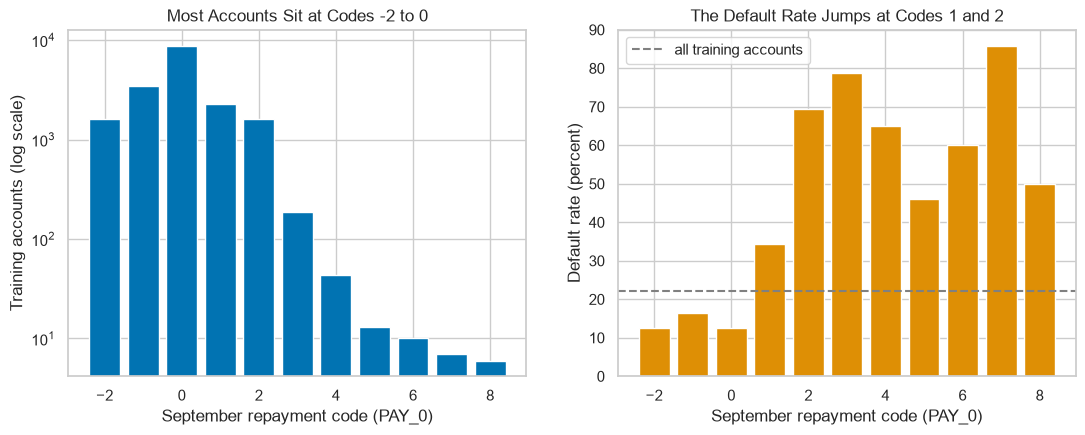

In [9]:
# accounts by code on a log axis, and the default rate by code with all training accounts' rate dashed
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.bar(by_code.index, by_code["accounts"])
left.set(yscale="log", xlabel="September repayment code (PAY_0)", ylabel="Training accounts (log scale)", title="Most Accounts Sit at Codes -2 to 0")
right.bar(by_code.index, by_code["default_rate"] * 100, color="C1")
right.axhline(y_train.mean() * 100, color="gray", linestyle="--", label="all training accounts")
right.set(xlabel="September repayment code (PAY_0)", ylabel="Default rate (percent)", title="The Default Rate Jumps at Codes 1 and 2")
right.legend()
plt.show()

Codes -2, -1 and 0 hold 13,846 of the 18,000 accounts, and their default rates do not rise with the code.

From code 1 the rate jumps: 34.4 percent at 1 and 69.5 percent at 2.

Codes 4 to 8 hold only 79 accounts between them, so their rates jump about.

**One column, `PAY_0`, carries today's neuron.**

# One Neuron by Hand

## A Neuron

A **neuron** multiplies each input by a **weight**, adds an **intercept** (Keras names it the **bias**), and passes the sum through an **activation**.
Today's neuron has one input, x, the account's `PAY_0`, so its weighted sum is z = b + w x.
Its activation is the sigmoid, 1 / (1 + exp(-z)), Course 4's Day 6 S curve, so its output sits between 0 and 1.
Following one account through these steps is the **forward pass**, and drawn as boxes joined by arrows it is a **computation graph**.

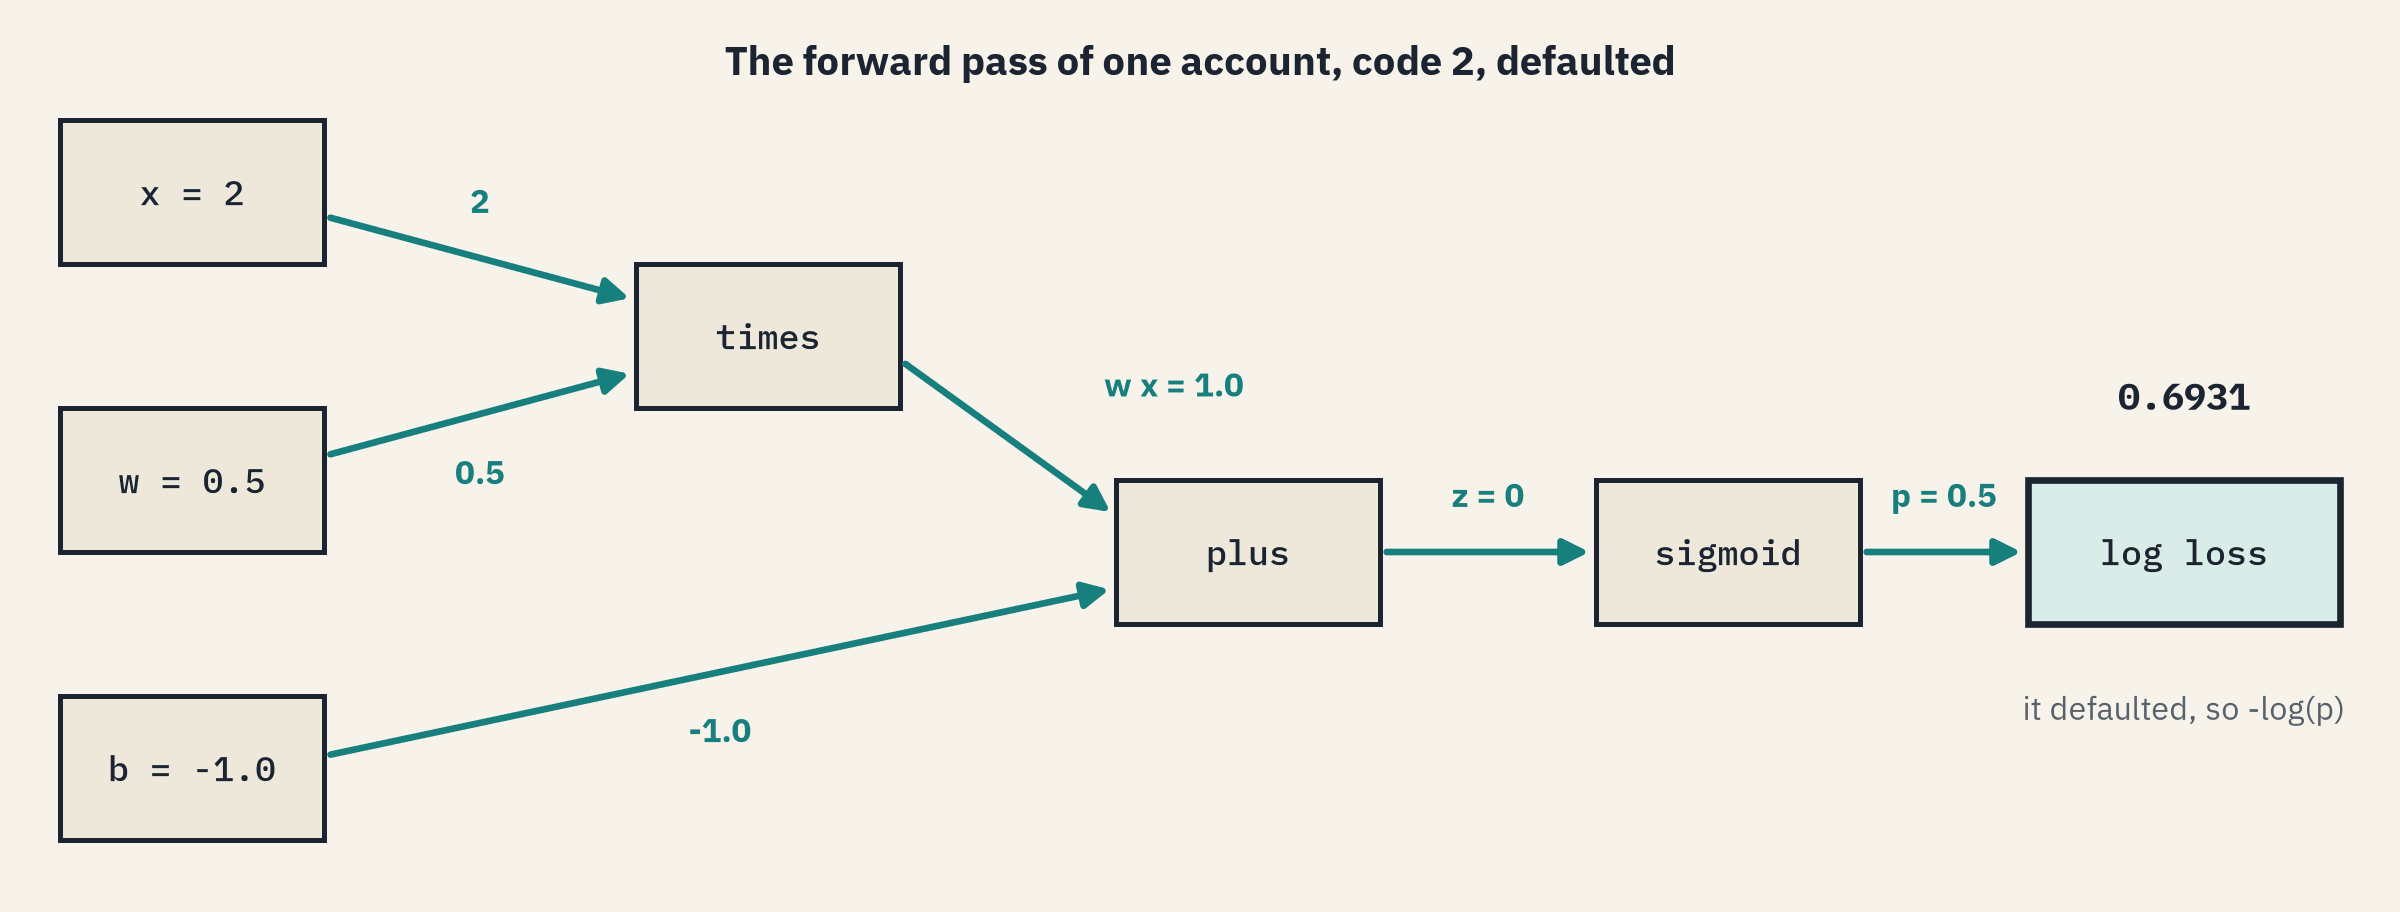

An account at code 2 that defaulted, at w = 0.5 and b = -1.0: z = 0, an output of 0.5, and a log loss of 0.6931.

## The Starting Neuron

The fit starts from w = 0.5 and b = -1.0, chosen only to start somewhere.

In [10]:
# the neuron's output: the sigmoid of b + w x
def output(w, b, x):
    """The neuron's output for inputs x: the sigmoid of b + w x, between 0 and 1."""
    return 1 / (1 + np.exp(-(b + w * x)))

In [11]:
# the training accounts' September codes and outcomes, as float64 arrays
x_pay = X_train["PAY_0"].to_numpy(dtype=float)
outcome = y_train.to_numpy(dtype=float)

# the starting neuron's output for the first five training accounts
print("Codes:  ", x_pay[:5])
print("Outputs:", output(0.5, -1.0, x_pay[:5]).round(4))

Codes:   [ 0.  0. -1.  0.  0.]
Outputs: [0.2689 0.2689 0.1824 0.2689 0.2689]


In [12]:
# the mean output over all 18,000 accounts beside the share that defaulted, and how many different outputs there are
start = output(0.5, -1.0, x_pay)
print("Mean output:", round(start.mean(), 4), "| default rate:", round(outcome.mean(), 4))
print("Different outputs:", len(np.unique(start)))

Mean output: 0.2795 | default rate: 0.2212
Different outputs: 11


Eleven codes, eleven outputs: the neuron sees nothing but the code.

On average the starting outputs sit above the default rate.

## The Loss

An account's **log loss** (Course 4's Day 6) is -log(p) if it defaulted and -log(1 - p) if it paid.
Their average, the **mean log loss**, is the **loss**: the one number fitting lowers.

In [13]:
# the mean log loss of the neuron's outputs against the outcomes
def mean_log_loss(w, b, x, y):
    """The mean log loss of the neuron at w and b on inputs x and outcomes y (1 defaulted, 0 paid)."""
    p = output(w, b, x)
    return np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p)))

In [14]:
# the starting loss, and scikit-learn's log_loss on the same outputs as a check
print("Mean log loss:", mean_log_loss(0.5, -1.0, x_pay, outcome))
print("log_loss:     ", log_loss(outcome, start))

Mean log loss: 0.4876206668388403
log_loss:      0.4876206668388403


Outputs: [0.1192 0.2689 0.5   ] | if defaulted: [2.1269 1.3133 0.6931] | if paid: [0.1269 0.3133 0.6931]


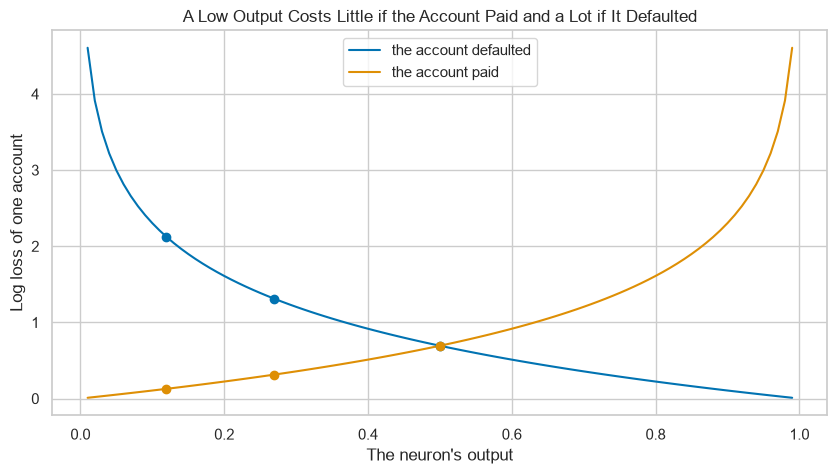

In [15]:
# one account's log loss at every output, if it defaulted and if it paid; the start's outputs at codes -2, 0 and 2 marked
marks = output(0.5, -1.0, np.array([-2.0, 0.0, 2.0]))
print("Outputs:", marks.round(4), "| if defaulted:", (-np.log(marks)).round(4), "| if paid:", (-np.log(1 - marks)).round(4))
p_line = np.linspace(0.01, 0.99, 99)
plt.plot(p_line, -np.log(p_line), label="the account defaulted")
plt.plot(p_line, -np.log(1 - p_line), label="the account paid")
plt.scatter(marks, -np.log(marks), color="C0", zorder=3)
plt.scatter(marks, -np.log(1 - marks), color="C1", zorder=3)
plt.xlabel("The neuron's output")
plt.ylabel("Log loss of one account")
plt.title("A Low Output Costs Little if the Account Paid and a Lot if It Defaulted")
plt.legend()
plt.show()

A defaulter at code -2, with an output of 0.1192, costs 2.1269; a paid account there costs 0.1269.

At code 2 the output is 0.5, and either outcome costs 0.6931.

**0.4876 is the number to lower, and the next section works out which way w and b should move.**

# The Gradient by Hand

## The Slope of the Loss for Each Weight

The **gradient** is one slope per weight: how fast the loss changes as that weight moves with the others held still.
For one account the slope of its log loss in z is p - y, the gradient Course 5's Day 8 gave boosting.
Since z = b + w x, the slope for w is the average of (p - y) x, and the slope for b the average of (p - y).
A negative slope says the loss falls as the weight rises.

In [16]:
# both slopes of the mean log loss, straight from the formulas above
def gradient(w, b, x, y):
    """The slopes of the mean log loss for w and for b: the averages of (p - y) x and of (p - y)."""
    p = output(w, b, x)
    return np.mean((p - y) * x), np.mean(p - y)

**Predict 1**

The starting neuron's mean output is 0.2795 and the default rate 0.2212.

Q. Write down the slope for b at the start, to four places.

## The Gradient at the Start

In [17]:
# both slopes at the starting neuron
g_w, g_b = gradient(0.5, -1.0, x_pay, outcome)
print("Slope for w:", g_w)
print("Slope for b:", g_b)

Slope for w: -0.03391581914014993
Slope for b: 0.05828373470535682


### Interpretation of the Gradient

The slope for w is negative, so raising w lowers the loss.

The slope for b is the mean output less the default rate: the outputs run high on average, so b should fall.

## What a Gradient Looks Like

A **tangent** is the straight line that touches a curve at one point with the curve's slope there.

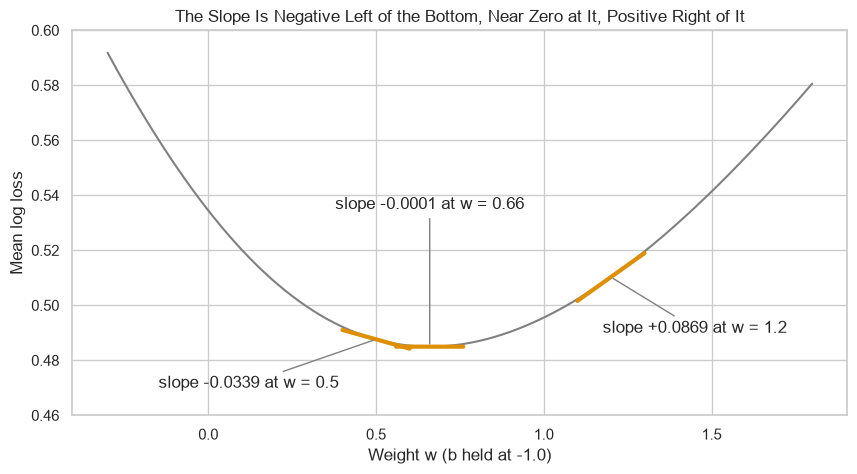

In [18]:
# the loss as w moves with b held at -1.0, and the tangent at three weights, each labelled with its slope
w_line = np.linspace(-0.3, 1.8, 200)
plt.plot(w_line, [mean_log_loss(wv, -1.0, x_pay, outcome) for wv in w_line], color="gray")
for w_point, label_at in [(0.5, (0.12, 0.47)), (0.66, (0.66, 0.535)), (1.2, (1.45, 0.49))]:
    slope_w = gradient(w_point, -1.0, x_pay, outcome)[0]
    level = mean_log_loss(w_point, -1.0, x_pay, outcome)
    plt.plot([w_point - 0.1, w_point + 0.1], [level - 0.1 * slope_w, level + 0.1 * slope_w], color="C1", linewidth=3)
    plt.annotate(f"slope {slope_w:+.4f} at w = {w_point}", (w_point, level), xytext=label_at, ha="center", arrowprops={"arrowstyle": "-", "color": "gray"})
plt.ylim(0.46, 0.6)
plt.xlabel("Weight w (b held at -1.0)")
plt.ylabel("Mean log loss")
plt.title("The Slope Is Negative Left of the Bottom, Near Zero at It, Positive Right of It")
plt.show()

At w = 0.5 the tangent falls to the right: move right.

At 0.66 it is flat: the bottom of this slice, with b held at -1.0.

At 1.2 it rises: move left, and faster, since it is steeper.

**The sign says which way, the size how steep: next, step that way again and again.**

# Gradient Descent by Hand

## One Step

**Gradient descent** moves each weight against its slope: w becomes w - (learning rate) times (slope for w), and b the same.
The **learning rate** sets the size of each **step**, as it did for boosting in Course 5's Day 7.
Every step here uses all 18,000 training accounts, a **full batch**.

In [19]:
# one step at a learning rate of 1: each weight moves against its slope
learning_rate = 1.0
g_w, g_b = gradient(0.5, -1.0, x_pay, outcome)
w_one, b_one = 0.5 - learning_rate * g_w, -1.0 - learning_rate * g_b
print("w:", round(w_one, 4), "| b:", round(b_one, 4), "| loss:", round(mean_log_loss(w_one, b_one, x_pay, outcome), 4))

w: 0.5339 | b: -1.0583 | loss: 0.4834


One step lowered the loss from 0.4876 to 0.4834.

**Predict 2**

The first step moves the weight from 0.5000 to 0.5339.
Course 4's Day 6 fitted this weight at 0.7702.

Q. Write down the weight after 10 steps at a learning rate of 1.

## A Hundred Steps

In [20]:
# the step above, repeated: the weights and the loss after each step, from w = 0.5 and b = -1.0
def descend(rate, steps):
    """The weights and the mean log loss on the training accounts after each of `steps` gradient steps."""
    w, b = 0.5, -1.0
    rows = [{"step": 0, "w": w, "b": b, "loss": mean_log_loss(w, b, x_pay, outcome)}]
    for step in range(1, steps + 1):
        g_w, g_b = gradient(w, b, x_pay, outcome)
        w, b = w - rate * g_w, b - rate * g_b
        rows.append({"step": step, "w": w, "b": b, "loss": mean_log_loss(w, b, x_pay, outcome)})
    return pd.DataFrame(rows).set_index("step")

In [21]:
# 100 steps at a learning rate of 1, shown at eight of them
path = descend(1.0, 100)
path.loc[[0, 1, 2, 5, 10, 20, 50, 100]].round(6)

,w,b,loss
step,,,
0,0.500000,-1.000000,0.487621
1,0.533916,-1.058284,0.483442
2,0.562693,-1.107029,0.480484
5,0.627347,-1.212828,0.475651
10,0.691431,-1.310600,0.472997
20,0.745467,-1.386201,0.472084
50,0.769413,-1.417526,0.471994
100,0.770210,-1.418545,0.471993


The weight climbs fast at first, then creeps: most of the way is covered in the first 20 steps.

The loss falls on every step shown and barely moves after step 50.

## The Same Curve as Course 4's Day 6

In [22]:
# Course 4's Day 6 fit of the same curve by statsmodels, beside the hand fit after 100 steps
w_fit, b_fit = path.loc[100, "w"], path.loc[100, "b"]
logit_pay = sm.Logit(y_train, sm.add_constant(X_train[["PAY_0"]])).fit(disp=0)
print("statsmodels: w", logit_pay.params["PAY_0"], "| b", logit_pay.params["const"])
print("100 steps:   w", w_fit, "| b", b_fit)
print("gaps:", f"{abs(w_fit - logit_pay.params['PAY_0']):.1e}", f"{abs(b_fit - logit_pay.params['const']):.1e}")

statsmodels: w 0.7702122576513862 | b -1.4185478976708692
100 steps:   w 0.7702096127618189 | b -1.4185445177803455
gaps: 2.6e-06 3.4e-06


A hundred plain steps land within a few millionths of Course 4's statsmodels fit.

In [23]:
# the mean log loss on a 60 x 60 grid of weights close around the steps, and the size of both slopes after every step
w_near = np.linspace(0.42, 0.88, 60)
b_near = np.linspace(-1.52, -0.94, 60)
near_map = np.array([[mean_log_loss(wv, bv, x_pay, outcome) for wv in w_near] for bv in b_near])
slopes = np.abs([gradient(wv, bv, x_pay, outcome) for wv, bv in zip(path["w"], path["b"])])
print(f"Lowest loss on the grid: {near_map.min():.4f}")
print("Slope for w at steps 0, 50 and 100:", slopes[[0, 50, 100], 0])
print("Slope for w at step 100 as a share of step 99:", round(slopes[100, 0] / slopes[99, 0], 3))

Lowest loss on the grid: 0.4720
Slope for w at steps 0, 50 and 100: [3.39158191e-02 8.63007880e-05 2.85486701e-07]
Slope for w at step 100 as a share of step 99: 0.892


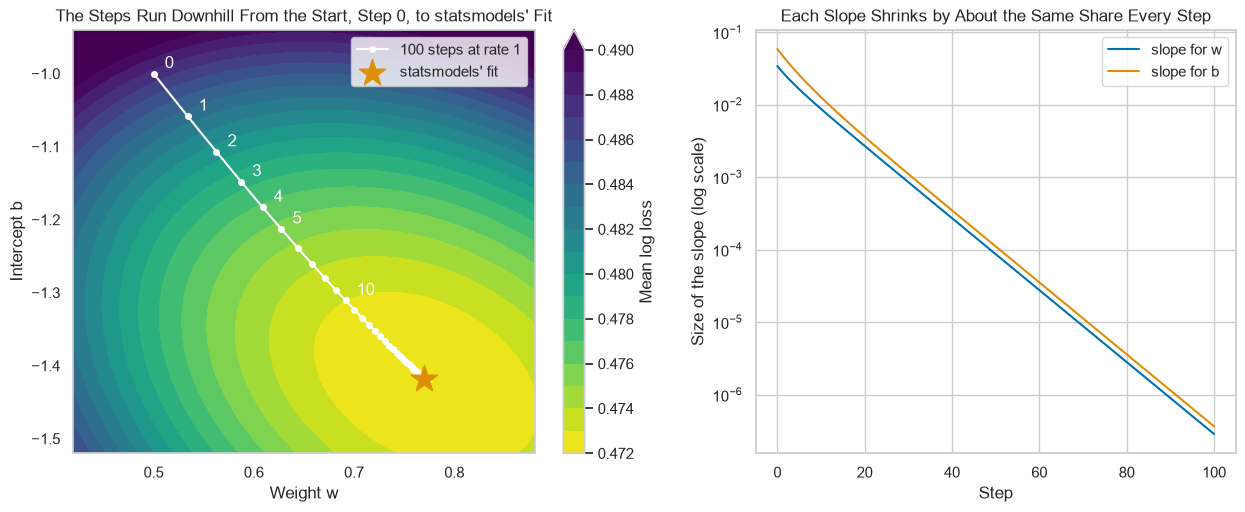

In [24]:
# left: the map, the steps with 0 to 5 and 10 numbered, statsmodels' fit starred; right: each slope's size by step
# (extend="max" paints every loss above the top level in the top level's colour)
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5), width_ratios=[1.2, 1])
fig.colorbar(left.contourf(w_near, b_near, near_map, levels=np.linspace(0.472, 0.49, 19), extend="max", cmap="viridis_r"), ax=left, label="Mean log loss")
left.plot(path["w"], path["b"], marker="o", markersize=4, color="white", label="100 steps at rate 1")
left.scatter(logit_pay.params["PAY_0"], logit_pay.params["const"], marker="*", s=400, color="C1", zorder=3, label="statsmodels' fit")
for k in [0, 1, 2, 3, 4, 5, 10]:
    left.annotate(k, (path.loc[k, "w"], path.loc[k, "b"]), xytext=(8, 4), textcoords="offset points", color="white", fontsize=12)
left.set(xlabel="Weight w", ylabel="Intercept b", title="The Steps Run Downhill From the Start, Step 0, to statsmodels' Fit")
left.legend(loc="upper right")
right.plot(path.index, slopes[:, 0], label="slope for w")
right.plot(path.index, slopes[:, 1], label="slope for b")
right.set(yscale="log", xlabel="Step", ylabel="Size of the slope (log scale)", title="Each Slope Shrinks by About the Same Share Every Step")
right.legend()
plt.show()

The steps run almost straight down the map to statsmodels' star, each one shorter than the last.

Each step's slope is 0.85 to 0.89 of the one before, close to a straight line on the log axis.

The steps shrink because the slopes shrink: the learning rate stays at 1 throughout.

## The Fitted Curve Against the Accounts

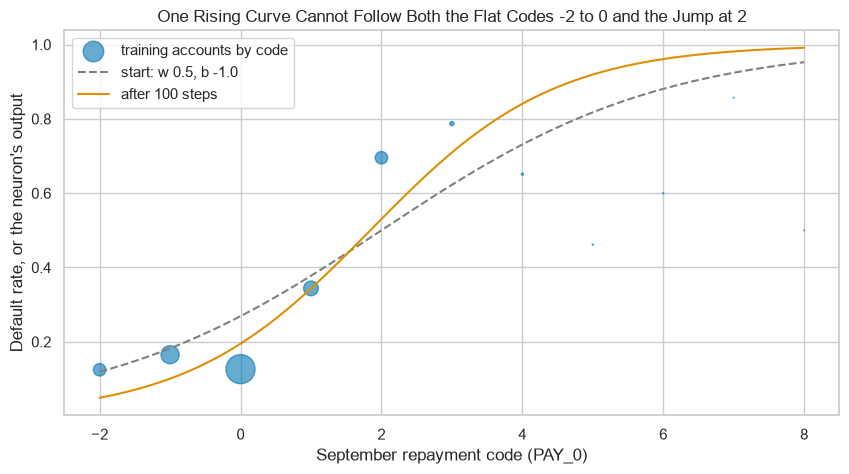

In [25]:
# the training default rate by code, dots sized by accounts, under the starting curve and the fitted curve
code_line = np.linspace(-2, 8, 200)
plt.scatter(by_code.index, by_code["default_rate"], s=by_code["accounts"] / 20, alpha=0.6, label="training accounts by code")
plt.plot(code_line, output(0.5, -1.0, code_line), linestyle="--", color="gray", label="start: w 0.5, b -1.0")
plt.plot(code_line, output(w_fit, b_fit, code_line), color="C1", label="after 100 steps")
plt.xlabel("September repayment code (PAY_0)")
plt.ylabel("Default rate, or the neuron's output")
plt.title("One Rising Curve Cannot Follow Both the Flat Codes -2 to 0 and the Jump at 2")
plt.legend()
plt.show()

In [26]:
# the fitted output beside each code's default rate
by_code.assign(output=output(w_fit, b_fit, by_code.index.to_numpy(dtype=float))).round(4)

,accounts,default_rate,output
PAY_0,,,
-2,1620,0.1247,0.0493
-1,3419,0.1653,0.1008
0,8807,0.1264,0.1949
1,2269,0.3438,0.3434
2,1618,0.6953,0.5304
3,188,0.7872,0.7093
4,43,0.6512,0.8405
5,13,0.4615,0.9193
6,10,0.6000,0.9609


At code 1 the fitted output, 0.3434, matches the rate, 0.3438; at code 2 it falls well short, 0.5304 against 0.6953.

Codes -2 to 0 have a flat rate, but one weight can only draw a rising curve through them.

Day 3's hidden layer is how a network bends it.

## Scoring the Neuron on the Validation Accounts

In [27]:
# the validation accounts' September codes and outcomes
x_pay_valid = X_valid["PAY_0"].to_numpy(dtype=float)
outcome_valid = y_valid.to_numpy(dtype=float)

# the mean log loss at the start and after 100 steps, and the fitted neuron's ROC AUC
print(f"Validation log loss, start: {mean_log_loss(0.5, -1.0, x_pay_valid, outcome_valid):.4f}")
print(f"Validation log loss, after 100 steps: {mean_log_loss(w_fit, b_fit, x_pay_valid, outcome_valid):.4f}")
print(f"Validation ROC AUC: {roc_auc_score(outcome_valid, output(w_fit, b_fit, x_pay_valid)):.4f}")

Validation log loss, start: 0.4934
Validation log loss, after 100 steps: 0.4820
Validation ROC AUC: 0.6834


On accounts it never saw, the fitted neuron scores 0.4820, the number Course 4's Day 6 printed for its `PAY_0` fit.

**A hundred plain steps land on Course 4's logistic regression: one neuron fitted by gradient descent is a logistic regression, Day 2's subject.**

# The Learning Rate

**Predict 3**

At a learning rate of 1 the loss fell on every step.

Q. Sketch the loss over 40 steps at a learning rate of 20.

## A Learning Rate of 20

In [28]:
# 40 steps at a learning rate of 20 from the same start: the first eight losses, the highest and the last
fast = descend(20.0, 40)
print(fast["loss"].head(8).round(4).tolist())
print("Highest:", round(fast["loss"].max(), 4), "at step", fast["loss"].idxmax(), "| step 40:", round(fast["loss"].iloc[-1], 4))

[0.4876, 0.5042, 0.5039, 0.6917, 1.123, 1.4305, 0.6226, 0.7859]
Highest: 1.4305 at step 5 | step 40: 0.8375


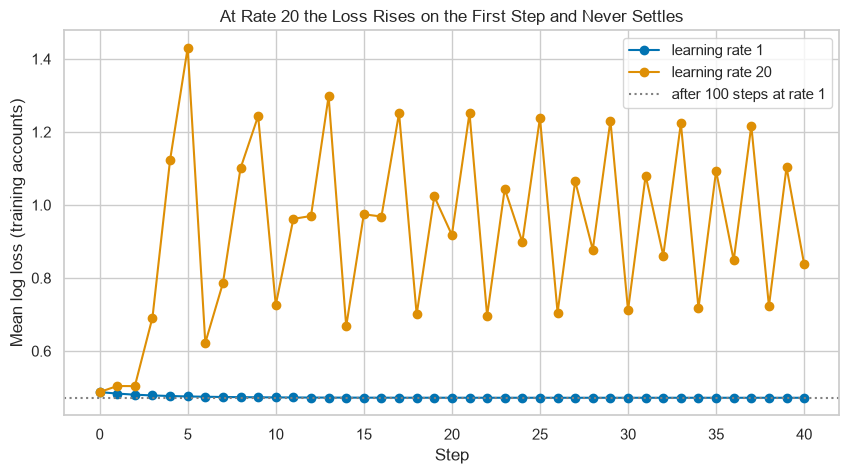

In [29]:
# the loss by step at rates 1 and 20, the loss after 100 steps at rate 1 dotted
plt.plot(path.loc[:40, "loss"], marker="o", label="learning rate 1")
plt.plot(fast["loss"], marker="o", label="learning rate 20")
plt.axhline(path.loc[100, "loss"], color="gray", linestyle=":", label="after 100 steps at rate 1")
plt.xlabel("Step")
plt.ylabel("Mean log loss (training accounts)")
plt.title("At Rate 20 the Loss Rises on the First Step and Never Settles")
plt.legend()
plt.show()

The first step at rate 20 raises the loss, and it jumps about for all 40 steps, ending above where it started.

A step so large that it crosses the bottom and lands higher up the other side is an **overshoot**.

## Your Turn: Pick a Rate

The slider draws the steps over a wider map of the loss, worked out once here so that a move of the slider only draws.

In [30]:
# the mean log loss on a wider 60 x 60 grid of weights, for the slider
w_values = np.linspace(-0.5, 2.0, 60)
b_values = np.linspace(-2.5, 0.5, 60)
loss_map = np.array([[mean_log_loss(wv, bv, x_pay, outcome) for wv in w_values] for bv in b_values])

Move the slider to find the largest learning rate at which the loss falls on every step.

In [31]:
# your turn: move the learning rate and watch 100 steps on the loss map and the loss by step
def draw_descent(rate=5.0):
    steps = descend(rate, 100)
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5))
    left.contour(w_values, b_values, loss_map, levels=20, cmap="viridis_r")
    left.plot(steps["w"], steps["b"], marker="o", markersize=3, color="C1")
    left.set(xlim=(-0.5, 2.0), ylim=(-2.5, 0.5), xlabel="Weight w", ylabel="Intercept b", title=f"100 Steps at a Learning Rate of {rate}")
    right.plot(steps["loss"], marker="o", markersize=3, color="C1")
    right.set(xlabel="Step", ylabel="Mean log loss (training accounts)", title=f"Lowest {steps['loss'].min():.4f}, Last {steps['loss'].iloc[-1]:.4f}")
    plt.show()

interact(draw_descent, rate=(0.5, 20.0, 0.5));

interactive(children=(FloatSlider(value=5.0, description='rate', max=20.0, min=0.5, step=0.5), Output()), _dom…

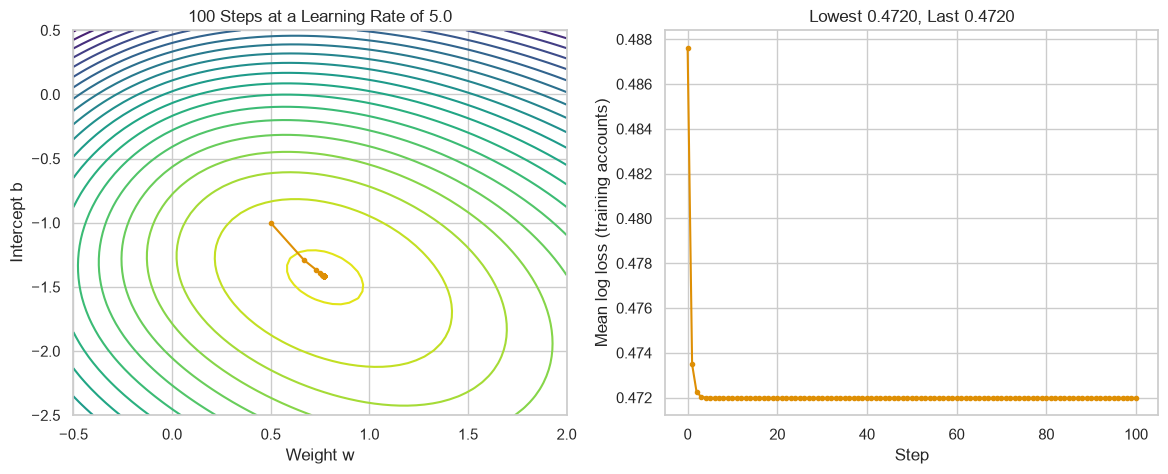

In [32]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_descent(rate=5.0)

In [33]:
# five rates near the edge: on how many of 100 steps the loss rose, the largest change in one step, and where it ended
for rate in [8.5, 9.0, 10.0, 12.0, 15.0]:
    losses = descend(rate, 100)["loss"]
    print(f"rate {rate}: rose on {(losses.diff() > 0).sum()} steps | largest change {losses.diff().max():+.1e} | last {losses.iloc[-1]:.4f}")

rate 8.5: rose on 0 steps | largest change -6.8e-15 | last 0.4720
rate 9.0: rose on 84 steps | largest change +5.7e-06 | last 0.4723
rate 10.0: rose on 57 steps | largest change +7.4e-03 | last 0.5235
rate 12.0: rose on 52 steps | largest change +4.2e-02 | last 0.6173
rate 15.0: rose on 50 steps | largest change +1.7e-01 | last 0.7072


At 8.5 the loss falls on every step, with both weights moving.

At 9 it rises on 84 of the 100 steps, by tiny amounts, and still ends low.

From 10 on it ends above the starting 0.4876.

## Why Large Steps Bounce

Holding the intercept at its fitted value leaves one weight to move, so each step can be drawn as a hop along one curve.

In [34]:
# the weight alone, the intercept held at its fitted value: 12 steps from w = 0.5 at four learning rates
hops = {}
for rate in [1, 5, 10, 15]:
    w_now = [0.5]
    for step in range(12):
        w_now.append(w_now[-1] - rate * gradient(w_now[-1], b_fit, x_pay, outcome)[0])
    hops[rate] = w_now
    print(f"rate {rate}:", np.round(w_now, 2))

rate 1: [0.5  0.55 0.59 0.63 0.65 0.67 0.69 0.71 0.72 0.73 0.74 0.74 0.75]
rate 5: [0.5  0.76 0.77 0.77 0.77 0.77 0.77 0.77 0.77 0.77 0.77 0.77 0.77]
rate 10: [0.5  1.02 0.61 0.91 0.67 0.86 0.71 0.82 0.73 0.8  0.74 0.79 0.75]
rate 15: [ 0.5   1.27  0.12  2.07 -0.11  2.53  0.03  2.26 -0.07  2.45 -0.    2.33
 -0.05]


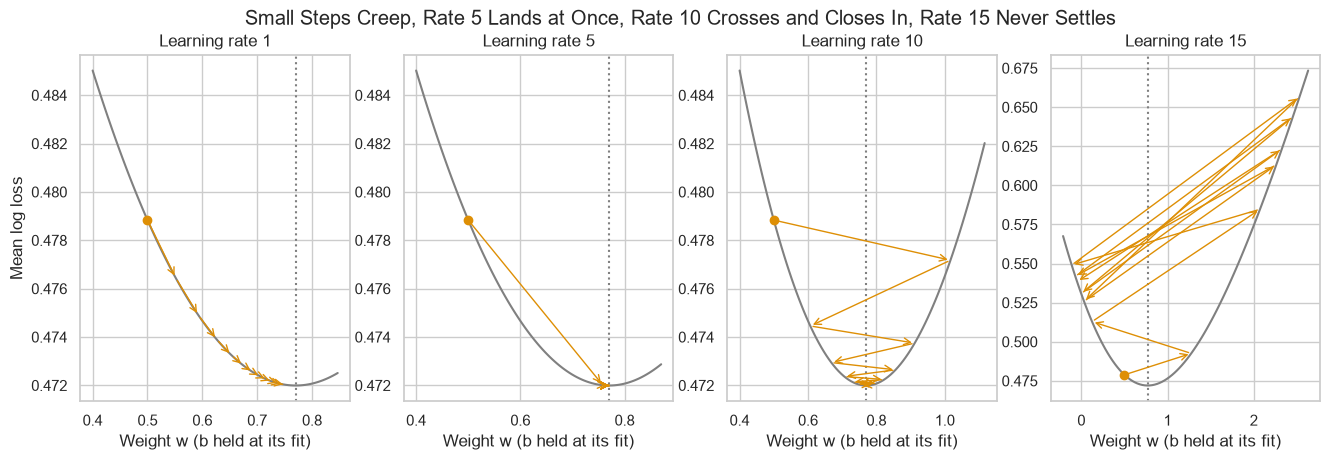

In [35]:
# each step as an arrow along the loss curve, from the weight before it to the weight after it; the start is the dot
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, rate in zip(axes, hops):
    w_line = np.linspace(min(hops[rate]) - 0.1, max(hops[rate]) + 0.1, 100)
    ax.plot(w_line, [mean_log_loss(wv, b_fit, x_pay, outcome) for wv in w_line], color="gray")
    levels = [mean_log_loss(wv, b_fit, x_pay, outcome) for wv in hops[rate]]
    ax.scatter(hops[rate][0], levels[0], color="C1", zorder=3)
    for k in range(12):
        ax.annotate("", (hops[rate][k + 1], levels[k + 1]), (hops[rate][k], levels[k]), arrowprops={"arrowstyle": "->", "color": "C1"})
    ax.axvline(w_fit, color="gray", linestyle=":")
    ax.set(title=f"Learning rate {rate}", xlabel="Weight w (b held at its fit)")
axes[0].set_ylabel("Mean log loss")
fig.suptitle("Small Steps Creep, Rate 5 Lands at Once, Rate 10 Crosses and Closes In, Rate 15 Never Settles")
plt.show()

At rate 1 the weight creeps toward the bottom, dotted, and has not reached it after 12 steps.

At 5 the first step lands almost on it.

At 10 each step crosses the bottom and lands a little closer.

At 15 the weight swings from about 0 to about 2.5 and back, and never closes in.

With only the weight moving, the edge sits at a higher rate than the slider's, where both weights move.

**Too small is slow and too large never arrives: a network has thousands of weights, so Days 6 and 7 come back to the learning rate.**

# Tensors

## The Device TensorFlow Uses

**TensorFlow** is the library under Keras: it holds the numbers, runs the arithmetic on a device, and works out gradients.

In [36]:
# the devices TensorFlow can use on this machine
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

One device here, the CPU.

The setup cell gave TensorFlow one thread and its plain CPU kernels, so every run prints the same last digits.

The logger line in the imports cell keeps out a notice TensorFlow prints on Windows, "TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11".

In Colab a GPU is chosen under "Runtime > Change Runtime Type", and Colab's FAQ says "Colab resources are not guaranteed and not unlimited" (https://research.google.com/colaboratory/faq.html).

Nothing in this course needs a GPU, and on one the last digits may differ from the saved ones.

## A Tensor

A **tensor** is TensorFlow's array: numbers laid along **axes**.
Its **rank** is the number of axes, its **shape** the length of each, and its **dtype** the kind of number it holds.

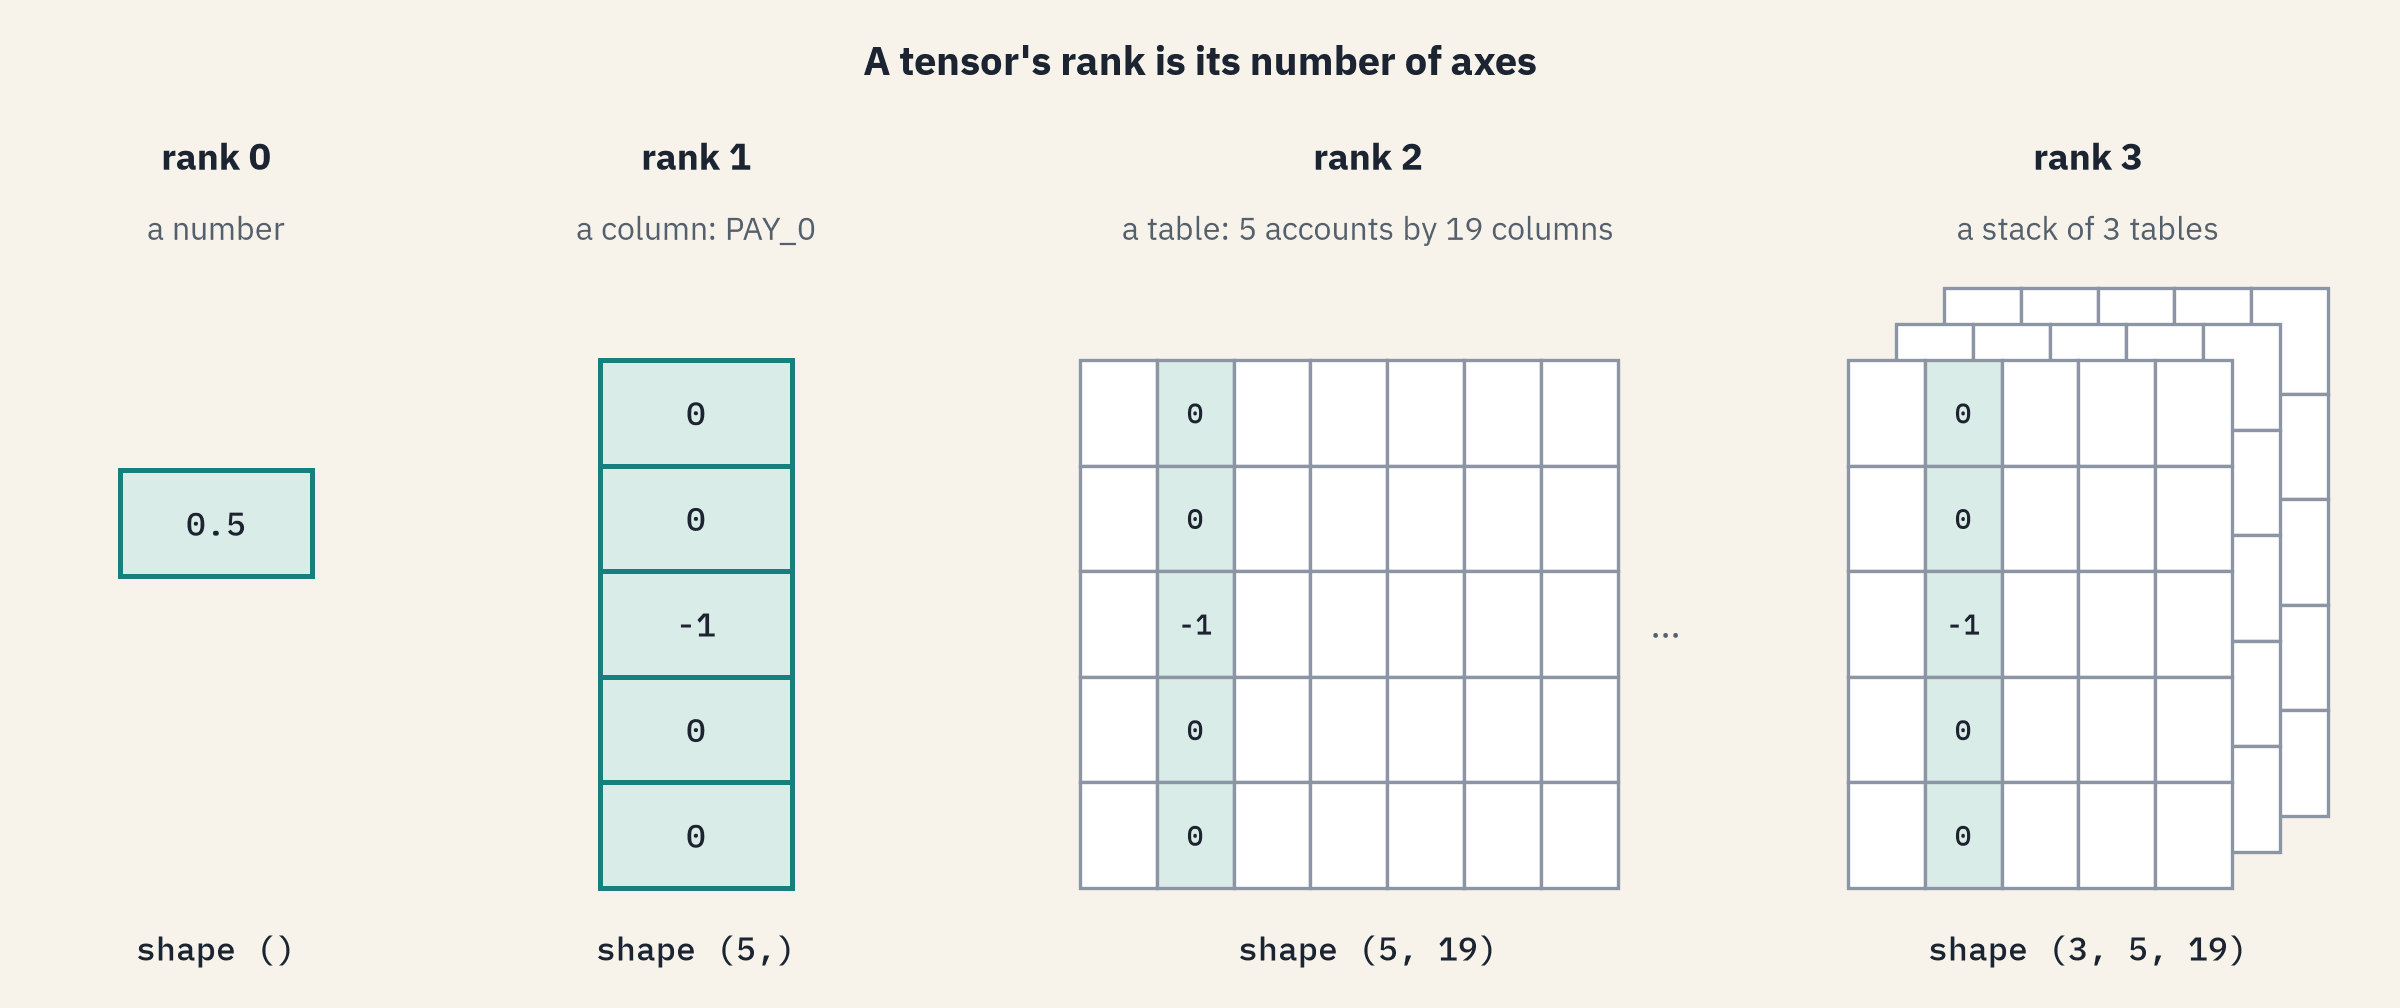

In [37]:
# rank 0: one number; rank 1: the 18,000 training codes; rank 2: five accounts by 19 columns
weight = tf.constant(0.5)
codes = tf.constant(x_pay)
five = tf.constant(X_train.head().to_numpy())
print(weight.shape, weight.dtype)
print(codes.shape, codes.dtype)
print(five.shape, five.dtype)

() <dtype: 'float32'>
(18000,) <dtype: 'float64'>
(5, 19) <dtype: 'int64'>


`tf.constant(0.5)` is float32, TensorFlow's default; the numpy arrays keep their float64 and int64.

float32 holds about 7 significant digits and float64 about 16; networks fit in float32.

## Mixing `float32` and `float64`

In [38]:
# the float32 weight times the float64 codes
weight * codes

InvalidArgumentError: cannot compute Mul as input #1(zero-based) was expected to be a float tensor but is a double tensor [Op:Mul] name: 

TensorFlow stops: the two tensors hold different dtypes.
`tf.cast(t, tf.float64)` turns a tensor into another dtype, and `.numpy()` turns a tensor back into a numpy array.

In [39]:
# the weight cast to float64, times the first five codes, plus the intercept: z for five accounts
(tf.cast(weight, tf.float64) * codes[:5] - 1.0).numpy()

array([-1. , -1. , -1.5, -1. , -1. ])

**TensorFlow never mixes precisions silently: from Day 2 every input is cast to float32 once.**

# The Gradient by TensorFlow

## One Account on the Tape

`tf.Variable` holds a tensor whose value can change, as a weight's does during a fit.

In [40]:
# the starting weights as variables
w_var = tf.Variable(0.5, dtype=tf.float64)
b_var = tf.Variable(-1.0, dtype=tf.float64)

Inside `with tf.GradientTape() as tape:` the tape records every operation, and `tape.gradient(loss, [w_var, b_var])` then gives each slope.

In [41]:
# one account at code 2 that defaulted: its log loss is -log(p)
with tf.GradientTape() as tape:
    p = tf.sigmoid(w_var * 2.0 + b_var)
    loss = -tf.math.log(p)
tape_w, tape_b = tape.gradient(loss, [w_var, b_var])
print("Slope for w:", tape_w.numpy(), "| slope for b:", tape_b.numpy())

Slope for w: -1.0 | slope for b: -0.5


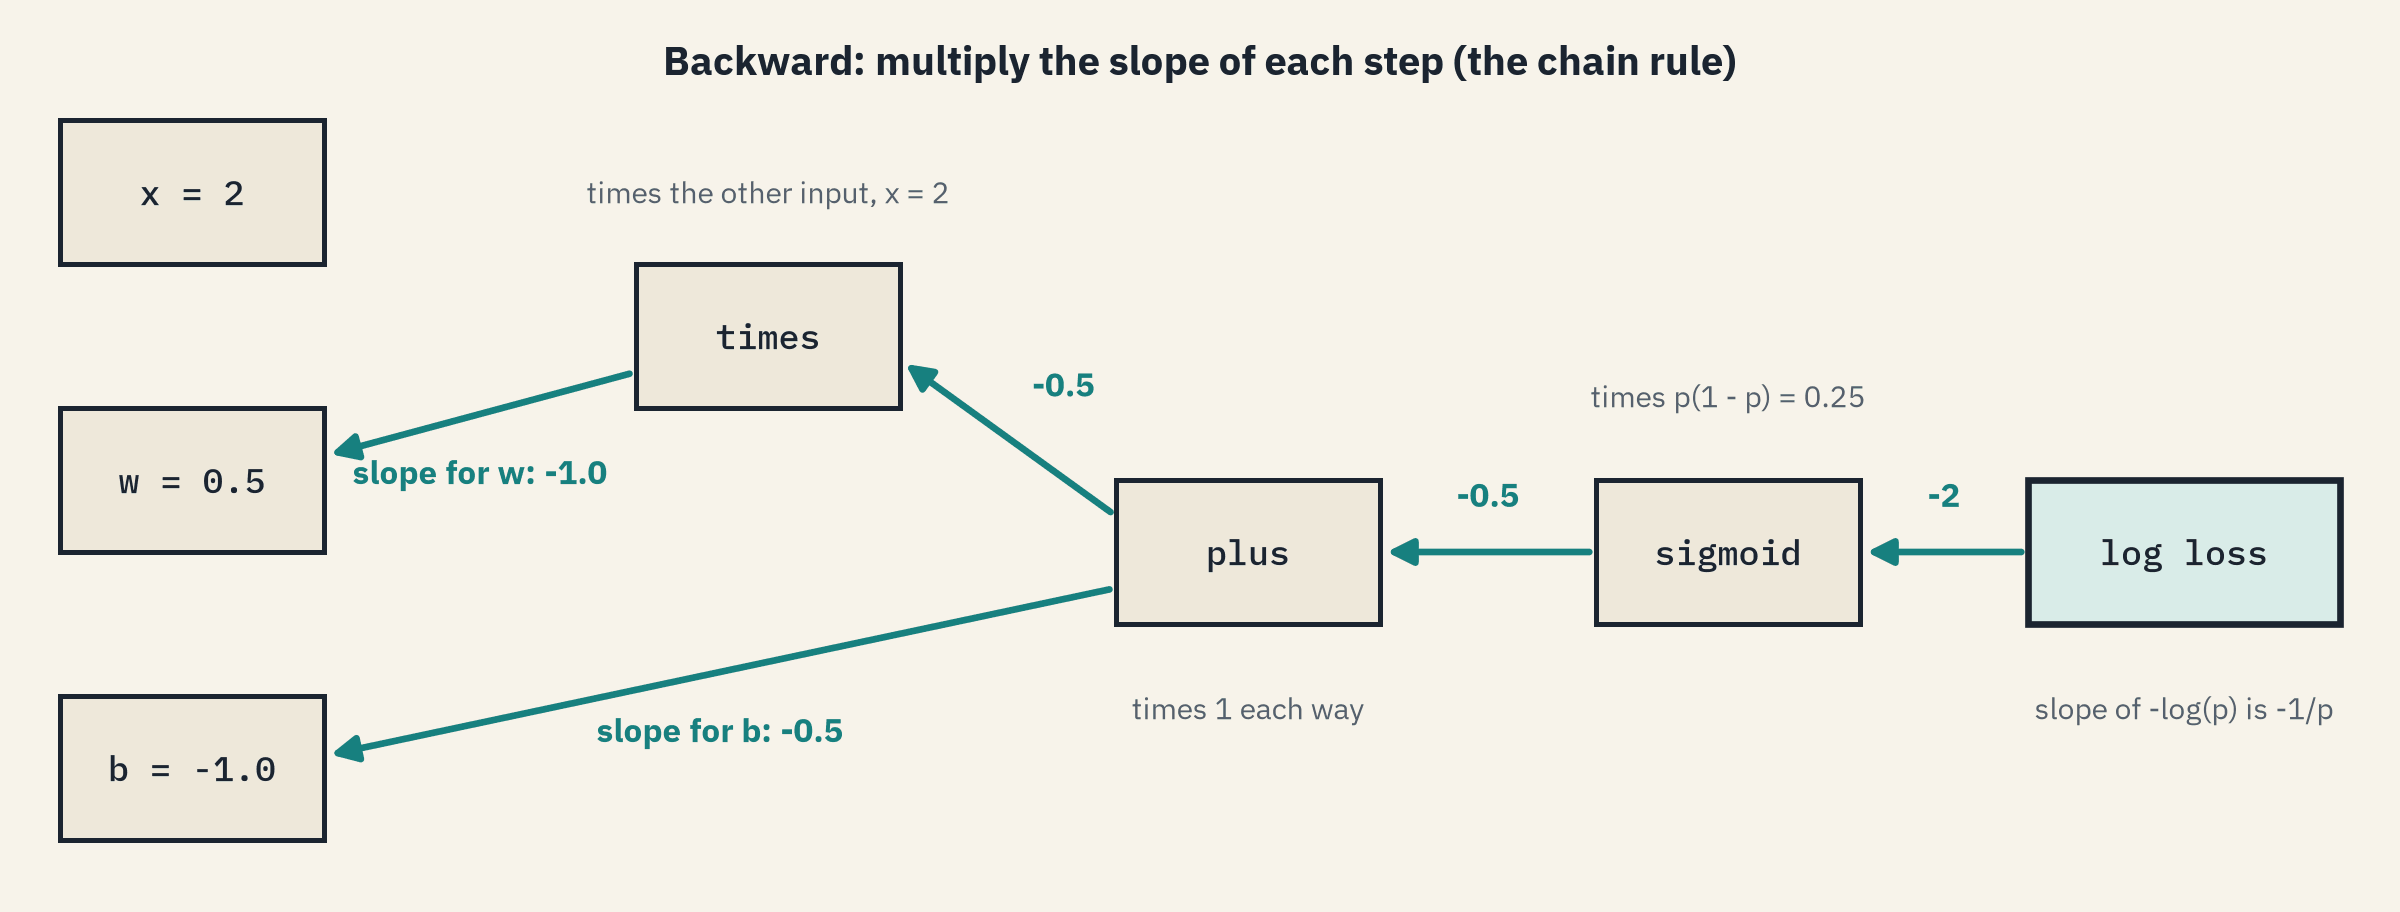

Backward, the tape multiplies the slope of each step: -2 times 0.25 is -0.5 in z, and times x = 2 is -1.0 for w.

Multiplying slopes along the graph is the **chain rule**, and doing it by machine is **automatic differentiation**.

## All 18,000 Accounts

`tf.sigmoid`, `tf.math.log` and `tf.reduce_mean` are numpy's operations as TensorFlow writes them.

In [42]:
# the mean log loss of all 18,000 training accounts on the tape, in float64
with tf.GradientTape() as tape:
    p = tf.sigmoid(w_var * x_pay + b_var)
    loss = -tf.reduce_mean(outcome * tf.math.log(p) + (1 - outcome) * tf.math.log(1 - p))
tape_w, tape_b = tape.gradient(loss, [w_var, b_var])
print("Tape:   ", tape_w.numpy(), tape_b.numpy())
print("By hand:", g_w, g_b)
print("Gaps:", f"{abs(tape_w.numpy() - g_w):.1e}", f"{abs(tape_b.numpy() - g_b):.1e}")

Tape:    -0.033915819140149905 0.058283734705356874
By hand: -0.03391581914014993 0.05828373470535682
Gaps: 2.8e-17 5.6e-17


### In `float32`

In [43]:
# the same in float32, the precision networks fit in
w32, b32 = tf.Variable(0.5), tf.Variable(-1.0)
with tf.GradientTape() as tape:
    p = tf.sigmoid(w32 * x_pay.astype("float32") + b32)
    loss = -tf.reduce_mean(outcome.astype("float32") * tf.math.log(p) + (1 - outcome.astype("float32")) * tf.math.log(1 - p))
tape_w32, tape_b32 = tape.gradient(loss, [w32, b32])
print("Gaps:", f"{abs(float(tape_w32) - g_w):.1e}", f"{abs(float(tape_b32) - g_b):.1e}")

Gaps: 8.9e-09 4.1e-09


The tape matches the formula to about 1e-16 in float64 and 1e-8 in float32, with no formula written.

The course reads a gap below 1e-12 in float64, or 1e-6 in float32, as the same number.

> STORY: In October 1986 Nature printed "Learning representations by back-propagating errors" by David E. Rumelhart, Geoffrey E. Hinton and Ronald J. Williams, volume 323, issue 6088, pages 533 to 536.
> Back-propagation is the name for what the tape just did, passing slopes backward from the loss to every weight.
> Only the publication's record was checked for this course; the paper itself was not read.
> Source: the Crossref record, https://api.crossref.org/works/10.1038/323533a0

**Predict 4**

Now all 19 raw columns, each with its own weight, every weight and the intercept at 0.

Q. Which column's slope is the largest in size, and roughly how large is it?

## Every Weight at Once

`tf.linalg.matvec(table, weights)` multiplies each row of a table by the weights and adds them up: z for every account at once.

In [44]:
# 19 weights and an intercept, all at 0, on the 19 raw columns of the training accounts
weights = tf.Variable(np.zeros(19))
bias = tf.Variable(0.0, dtype=tf.float64)
with tf.GradientTape() as tape:
    p = tf.sigmoid(tf.linalg.matvec(X_train.to_numpy(dtype=float), weights) + bias)
    loss = -tf.reduce_mean(outcome * tf.math.log(p) + (1 - outcome) * tf.math.log(1 - p))
tape_weights, tape_bias = tape.gradient(loss, [weights, bias])
all_slopes = pd.Series(np.append(tape_weights.numpy(), tape_bias.numpy()), index=FEATURES + ["intercept"])
all_slopes.round(3)

LIMIT_BAL    55515.444
PAY_0           -0.158
PAY_2           -0.169
PAY_3           -0.165
PAY_4           -0.166
PAY_5           -0.169
PAY_6           -0.169
BILL_AMT1    14826.439
BILL_AMT2    14072.976
BILL_AMT3    13491.679
BILL_AMT4    12296.554
BILL_AMT5    11350.324
BILL_AMT6    10871.944
PAY_AMT1      2065.381
PAY_AMT2      2201.193
PAY_AMT3      1830.205
PAY_AMT4      1711.609
PAY_AMT5      1689.639
PAY_AMT6      1904.452
intercept        0.279
dtype: float64

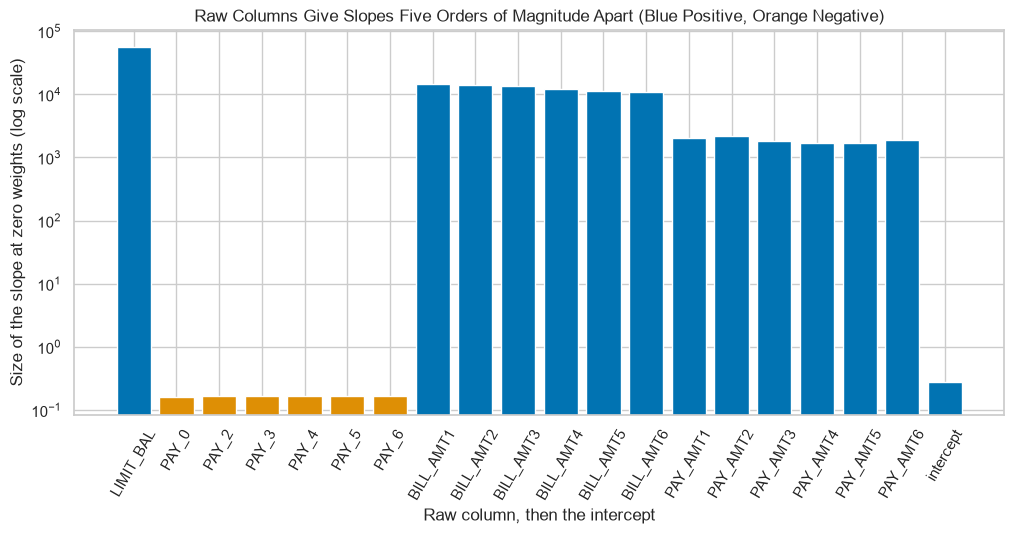

In [45]:
# the size of each slope on a log axis, blue where it is positive and orange where it is negative
colours = ["C0" if s > 0 else "C1" for s in all_slopes]
plt.figure(figsize=(12, 5))
plt.bar(all_slopes.index, all_slopes.abs(), color=colours)
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Raw column, then the intercept")
plt.ylabel("Size of the slope at zero weights (log scale)")
plt.title("Raw Columns Give Slopes Five Orders of Magnitude Apart (Blue Positive, Orange Negative)")
plt.show()

The amounts in NT dollars have slopes in the thousands; the repayment codes have slopes near 0.16.

One learning rate cannot suit slopes this far apart: a step that suits the codes throws the limit's weight far past any bottom.

**The tape gives every weight's slope in the same few lines; raw columns give slopes far apart in size, so Day 2 scales them and hands the loop to Keras.**

# Insights and Conclusion

One neuron is z = b + w x through a sigmoid, scored by its mean log loss, 0.4876 at the start.

Its gradient is the average of (p - y) x for w and of (p - y) for b.

100 full-batch steps at a learning rate of 1 landed within a few millionths of Course 4's statsmodels fit and scored 0.4820 on the validation accounts.

Past a learning rate of about 9 the full-batch steps overshoot.

The tape matched the hand gradient to about 1e-16 in float64 and 1e-8 in float32, with no formula written.

The outputs are the model's probability of default in this file, nothing more.

**`fit` in every later day runs this loop, on every weight of the network.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Make tensors and read their rank, shape and dtype.
* Compute one neuron's output and mean log loss by hand.
* Work out a gradient by hand and check it with `tf.GradientTape`.
* Fit a neuron by gradient descent and set it beside Course 4's logistic regression.
* Read what the learning rate does to the steps.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Second Input**

Add `LIMIT_BAL` in NT$10,000 as a second input beside `PAY_0`, with a weight of 0 for it, 0.5 for `PAY_0`, and an intercept of -1.0.

Q. Work out the slope of the mean log loss for the limit's weight on the training accounts, the average of (p - y) times the limit, and store it in `ex1_gradient_limit`.

In [47]:
# the limit in NT$10,000, and the outputs with its weight at 0
limit = X_train["LIMIT_BAL"].to_numpy(dtype=float) / 10_000
p_two = 1 / (1 + np.exp(-(-1.0 + 0.5 * x_pay + 0.0 * limit)))

# the slope for the limit's weight: the average of (p - y) times the limit
ex1_gradient_limit = np.mean((p_two - outcome) * limit)
print(ex1_gradient_limit)

1.488818799099081


The slope is positive, so the loss falls as the limit's weight moves below 0.

With the limit's weight at 0, the outputs are the starting neuron's outputs from the lesson.

In [48]:
check("Exercise 1 the slope for the limit's weight", ex1_gradient_limit, 1.488818799099081)

Exercise 1 the slope for the limit's weight: correct


### Exercise 2

**Three Rates, 50 Steps**

Q. Run 50 steps from the start at learning rates 0.1, 1 and 10 with `descend`, and store each last loss in `ex2_loss_01`, `ex2_loss_1` and `ex2_loss_10`.

In [49]:
# 50 steps at each rate, the last loss of each
ex2_loss_01 = descend(0.1, 50)["loss"].iloc[-1]
ex2_loss_1 = descend(1.0, 50)["loss"].iloc[-1]
ex2_loss_10 = descend(10.0, 50)["loss"].iloc[-1]
print(ex2_loss_01, ex2_loss_1, ex2_loss_10)

0.476013911102858 0.471993577517757 0.5235015654578791


At 0.1 the loss is still falling after 50 steps; at 1 it is at the bottom; at 10 it ends above the starting 0.4876.

In [50]:
check("Exercise 2 the loss after 50 steps at 0.1", ex2_loss_01, 0.476013911102858)
check("Exercise 2 the loss after 50 steps at 1", ex2_loss_1, 0.471993577517757)
check("Exercise 2 the loss after 50 steps at 10", ex2_loss_10, 0.5235015654578791)

Exercise 2 the loss after 50 steps at 0.1: correct
Exercise 2 the loss after 50 steps at 1: correct
Exercise 2 the loss after 50 steps at 10: correct


### Exercise 3

**The Loss Path as a Function**

Q. Write `loss_path(w, b, x, y, learning_rate, steps)`, which takes `steps` gradient steps from w and b and returns a list of the mean log loss after each one.
Run it for 30 steps at a learning rate of 3 from w = 0.5 and b = -1.0, and store the last loss in `ex3_last` and the list's length in `ex3_count`.

In [51]:
# the loss after each step, as a list
def loss_path(w, b, x, y, learning_rate, steps):
    """The mean log loss after each of `steps` gradient steps from w and b."""
    losses = []
    for step in range(steps):
        g_w, g_b = gradient(w, b, x, y)
        w, b = w - learning_rate * g_w, b - learning_rate * g_b
        losses.append(mean_log_loss(w, b, x, y))
    return losses

ex3_losses = loss_path(0.5, -1.0, x_pay, outcome, 3.0, 30)
ex3_last, ex3_count = ex3_losses[-1], len(ex3_losses)
print(ex3_last, ex3_count)

0.4719934865928594 30


At a rate of 3, 30 steps reach the bottom that rate 1 took about 50 to reach.

In [52]:
check("Exercise 3 the last loss after 30 steps at 3", ex3_last, 0.4719934865928594)
check("Exercise 3 the number of losses", ex3_count, 30)

Exercise 3 the last loss after 30 steps at 3: correct
Exercise 3 the number of losses: correct


### Exercise 4: AI check

**A Gradient That Is Too Big**

You asked an AI assistant for the neuron's gradient as a function.
This came back.
Run it beside the tape's slopes, then find the one bug.

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def neuron_gradient(w, b, x, y):
    """The slopes of the mean log loss for w and for b, averaged over the accounts."""
    p = 1 / (1 + np.exp(-(b + w * x)))
    return np.sum((p - y) * x), np.sum(p - y)

In [54]:
# its slopes at the starting neuron, beside the tape's float64 slopes
ai_w, ai_b = neuron_gradient(0.5, -1.0, x_pay, outcome)
print("Assistant:", round(ai_w, 4), round(ai_b, 4), "| tape:", round(float(tape_w), 6), round(float(tape_b), 6))
print("Ratio:", round(ai_w / float(tape_w), 1))

Assistant: -610.4847 1049.1072 | tape: -0.033916 0.058284
Ratio: 18000.0


Q. Fix the one wrong line and store the fixed function's slope for w at the starting neuron in `ex4_gradient_w`.

In [55]:
# the fix: average over the accounts, as the docstring says
def neuron_gradient(w, b, x, y):
    """The slopes of the mean log loss for w and for b, averaged over the accounts."""
    p = 1 / (1 + np.exp(-(b + w * x)))
    return np.mean((p - y) * x), np.mean(p - y)

ex4_gradient_w = neuron_gradient(0.5, -1.0, x_pay, outcome)[0]
print(ex4_gradient_w)

-0.03391581914014993


The return line summed over the accounts, so both slopes came out 18,000 times too big, one for each training account.

The signs were right, which is why the numbers looked plausible; a step at a learning rate of 1 would have thrown the weight about 610 units.

The fixed function matches the lesson's `gradient` to the last digit, and the tape within 1e-16.

In [56]:
check("Exercise 4 the fixed slope for w", ex4_gradient_w, -0.03391581914014993)

Exercise 4 the fixed slope for w: correct


## Congratulations!

You took apart the routine that fits every network in this course and rebuilt it by hand.
You wrote one neuron's output, its loss and its gradient, then stepped downhill a hundred times and landed on Course 4's logistic regression.
You watched a learning rate that was too large overshoot, and found the edge yourself with a slider.
You had TensorFlow's tape work out the same gradient with no formula written, and caught a gradient 18,000 times too big.
In Day 2, Keras runs this loop for you, and the one neuron becomes a logistic regression in a few lines.

[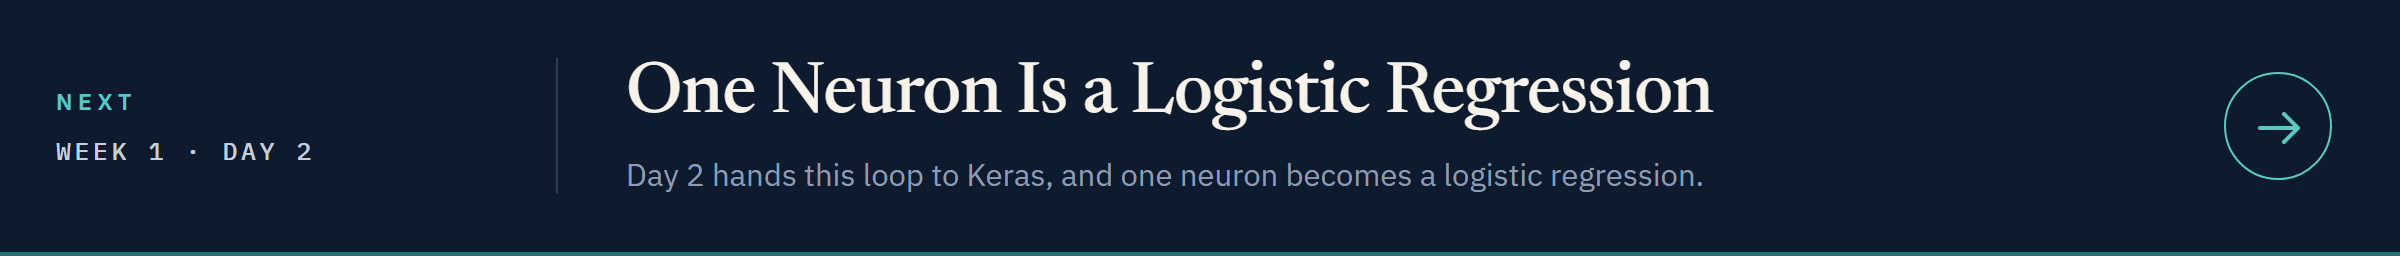](../day2/02_one_neuron_is_a_logistic_regression.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week1/day2/02_one_neuron_is_a_logistic_regression.ipynb)